In [1]:
library(tidyverse)
library(bigrquery)

# This query represents dataset "diabetes" for domain "fitbit_sleep_daily_summary" and was generated for All of Us Controlled Tier Dataset v8
dataset_57359454_fitbit_sleep_daily_summary_sql <- paste("
    SELECT
        sleep_daily_summary.person_id,
        sleep_daily_summary.sleep_date,
        sleep_daily_summary.is_main_sleep,
        sleep_daily_summary.minute_in_bed,
        sleep_daily_summary.minute_asleep,
        sleep_daily_summary.minute_after_wakeup,
        sleep_daily_summary.minute_awake,
        sleep_daily_summary.minute_restless,
        sleep_daily_summary.minute_deep,
        sleep_daily_summary.minute_light,
        sleep_daily_summary.minute_rem,
        sleep_daily_summary.minute_wake 
    FROM
        `sleep_daily_summary` sleep_daily_summary   
    WHERE
        PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_activity_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_plus_device_information = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_heart_rate_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_steps_intraday = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_daily_summary = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_fitbit_sleep_level = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                criteria.person_id 
            FROM
                (SELECT
                    DISTINCT person_id, entry_date, concept_id 
                FROM
                    `cb_search_all_events` 
                WHERE
                    (concept_id IN(SELECT
                        DISTINCT c.concept_id 
                    FROM
                        `cb_criteria` c 
                    JOIN
                        (SELECT
                            CAST(cr.id as string) AS id       
                        FROM
                            `cb_criteria` cr       
                        WHERE
                            concept_id IN (201820)       
                            AND full_text LIKE '%_rank1]%'      ) a 
                            ON (c.path LIKE CONCAT('%.', a.id, '.%') 
                            OR c.path LIKE CONCAT('%.', a.id) 
                            OR c.path LIKE CONCAT(a.id, '.%') 
                            OR c.path = a.id) 
                    WHERE
                        is_standard = 1 
                        AND is_selectable = 1) 
                    AND is_standard = 1 )) criteria ) )", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
fitbit_sleep_daily_summary_57359454_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "fitbit_sleep_daily_summary_57359454",
  "fitbit_sleep_daily_summary_57359454_*.csv")
message(str_glue('The data will be written to {fitbit_sleep_daily_summary_57359454_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_57359454_fitbit_sleep_daily_summary_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  fitbit_sleep_daily_summary_57359454_path,
  destination_format = "CSV")


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
The data will be written to gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260428/fitbit_sleep_daily_summary_57359454/fitbit_sleep_daily_summary_57359454_*.csv. Use this path when reading the data into your notebooks in the future.



In [4]:
# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {fitbit_sleep_daily_summary_57359454_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(is_main_sleep = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
diabetes_sleep <- read_bq_export_from_workspace_bucket(fitbit_sleep_daily_summary_57359454_path)

dim(diabetes_sleep)

head(diabetes_sleep, 5)

Loading gs://fc-secure-1d0240db-6bfa-4a11-a526-48cfbb0d664a/bq_exports/zqiu@researchallofus.org/20260428/fitbit_sleep_daily_summary_57359454/fitbit_sleep_daily_summary_57359454_000000000000.csv.



[1] 2524055      12

person_id,sleep_date,is_main_sleep,minute_in_bed,minute_asleep,minute_after_wakeup,minute_awake,minute_restless,minute_deep,minute_light,minute_rem,minute_wake
<dbl>,<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2625708,2021-12-19,true,180,157,0,23,NA,0,157,0,23
2625708,2021-09-09,true,180,157,0,23,NA,6,131,20,23
2612392,2021-03-05,false,180,157,6,23,NA,40,82,35,23
2584598,2022-04-28,false,180,157,0,23,NA,30,120,7,23
2627121,2023-08-13,false,180,157,0,23,NA,30,127,0,23


In [38]:
source('/home/jupyter/workspaces/temporaldigitalhealthphenotyping/ind_descriptive_func.R')

In [17]:
diabetes_sleep |>
  group_by(person_id, date) |>
  filter(n() > 1) |>
  ungroup() |>
  arrange(person_id, date) |>
  slice_head(n = 10)

person_id,date,is_main_sleep,minute_in_bed,minute_asleep,minute_after_wakeup,minute_awake,minute_restless,minute_deep,minute_light,minute_rem,minute_wake
<dbl>,<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1000976,2016-01-07,false,11,11,0,0,0,NA,NA,NA,NA
1000976,2016-01-07,true,60,60,0,0,0,NA,NA,NA,NA
1000976,2016-01-08,false,148,60,0,88,82,NA,NA,NA,NA
1000976,2016-01-08,true,163,100,13,50,59,NA,NA,NA,NA
1000976,2016-01-09,false,136,77,0,43,52,NA,NA,NA,NA
1000976,2016-01-09,true,433,234,0,167,189,NA,NA,NA,NA
1000976,2016-01-10,false,161,76,10,75,83,NA,NA,NA,NA
1000976,2016-01-10,true,396,201,12,183,190,NA,NA,NA,NA
1000976,2016-01-17,false,82,57,0,25,25,NA,NA,NA,NA


In [39]:
colnames(diabetes_sleep)[2] <- 'date'
diabetes_sleep_main <- diabetes_sleep |>
  filter(is_main_sleep == "true")

diabetes_sleep_nap <- diabetes_sleep |>
  filter(is_main_sleep == "false")

diabetes_sleep_sum <- sleep_sum_main_nap_func(df = diabetes_sleep)

In [40]:
wear_compliance_func(path.out = '/home/jupyter/workspaces/result/Diabetes/sleep/', df = diabetes_sleep_sum)

── Wear compliance ──
     n_days       followup_days   
 Min.   :   1.0   Min.   :   1.0  
 1st Qu.:  52.0   1st Qu.:  91.0  
 Median : 102.0   Median : 248.0  
 Mean   : 443.9   Mean   : 848.5  
 3rd Qu.: 592.5   3rd Qu.:1389.0  
 Max.   :3887.0   Max.   :4898.0  


`geom_smooth()` using formula = 'y ~ x'


   person_id           n_days         first_date           last_date         
 Min.   :1000976   Min.   :   1.0   Min.   :2009-11-18   Min.   :2015-08-31  
 1st Qu.:1848496   1st Qu.:  52.0   1st Qu.:2018-09-01   1st Qu.:2023-06-22  
 Median :3078203   Median : 102.0   Median :2022-07-16   Median :2023-09-28  
 Mean   :4091025   Mean   : 443.9   Mean   :2020-12-12   Mean   :2023-04-09  
 3rd Qu.:6158201   3rd Qu.: 592.5   3rd Qu.:2023-06-19   3rd Qu.:2023-10-01  
 Max.   :9995360   Max.   :3887.0   Max.   :2023-10-01   Max.   :2023-10-01  
 followup_days     missing_days     pct_missing       compliance_tier
 Min.   :   1.0   Min.   :   0.0   Min.   : 0.00   High (>90%):1184  
 1st Qu.:  91.0   1st Qu.:  17.0   1st Qu.:10.22   80-90%     : 622  
 Median : 248.0   Median :  64.0   Median :33.06   70-80%     : 477  
 Mean   : 848.5   Mean   : 404.6   Mean   :39.10   60-70%     : 421  
 3rd Qu.:1389.0   3rd Qu.: 451.5   3rd Qu.:65.77   50-60%     : 345  
 Max.   :4898.0   Max.   :3976.0  

NULL

In [41]:
patient_stats_main <- sleep_prep_stats(
    path.out = '/home/jupyter/workspaces/Data/',
    cohort = 'Diabetes',
    df = diabetes_sleep_main,
    main = 'main'
)
patient_stats_nap <- sleep_prep_stats(
    path.out = '/home/jupyter/workspaces/Data/',
    cohort = 'Diabetes',
    df = diabetes_sleep_nap,
    main = 'nap'
)

# A tibble: 7 × 9
  metric            N  Mean    SD Median    Q1    Q3    P5   P95
  <chr>         <int> <dbl> <dbl>  <dbl> <dbl> <dbl> <dbl> <dbl>
1 minute_asleep  4783 348.   85.2  361.  303.  405.  184.  461. 
2 minute_awake   4783  47.0  17.6   47.3  37.1  56.9  17.8  72.6
3 minute_deep    4638  53.0  16.3   52.4  41.5  63.8  27.4  80.2
4 minute_in_bed  4783 396.   96.3  412.  347.  460.  207.  524. 
5 minute_light   4638 248.   48.1  247.  217.  277.  175.  329. 
6 minute_rem     4638  71.5  22.9   71.7  56    87    33.5 107. 
7 minute_wake    4638  53.7  12.1   52.9  45.7  60.9  35.1  74.2
# A tibble: 7 × 9
  metric            N  Mean    SD Median     Q1    Q3     P5   P95
  <chr>         <int> <dbl> <dbl>  <dbl>  <dbl> <dbl>  <dbl> <dbl>
1 minute_asleep  4513 105.  27.9  103.    88.3  118.   66    148. 
2 minute_awake   4513  12.0  9.05   9.11   6.52  13.6   3.23  32.8
3 minute_deep    3276  24.1 11.1   23.6   17     30.5   6     42  
4 minute_in_bed  4513 118.  29.9  115    100

In [46]:
head(diabetes_sleep_sum)
patient_stats_sum <-sleep_prep_stats(df = diabetes_sleep_sum, path.out =  '/home/jupyter/workspaces/result/Diabetes/', cohort = 'Diabetes', main = "sum")

person_id,date,has_main_sleep,has_nap,n_records,minute_in_bed,minute_asleep,minute_awake,minute_restless,minute_deep,⋯,minute_wake,minute_after_wakeup,main_minute_in_bed,main_minute_asleep,main_minute_awake,main_minute_deep,main_minute_light,main_minute_rem,main_minute_wake,sleep_efficiency
<dbl>,<date>,<lgl>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1000976,2016-01-07,TRUE,TRUE,2,71,71,0,0,0,⋯,0,0,71,71,0,0,0,0,0,100.00000
1000976,2016-01-08,TRUE,TRUE,2,311,160,138,141,0,⋯,0,13,311,160,138,0,0,0,0,51.44695
1000976,2016-01-09,TRUE,TRUE,2,569,311,210,241,0,⋯,0,0,569,311,210,0,0,0,0,54.65729
1000976,2016-01-10,TRUE,TRUE,2,557,277,258,273,0,⋯,0,22,557,277,258,0,0,0,0,49.73070
1000976,2016-01-11,TRUE,FALSE,1,358,259,82,91,0,⋯,0,0,358,259,82,0,0,0,0,72.34637
1000976,2016-01-12,TRUE,FALSE,1,365,267,87,93,0,⋯,0,0,365,267,87,0,0,0,0,73.15068


# A tibble: 8 × 9
  metric               N  Mean    SD Median    Q1    Q3     P5   P95
  <chr>            <int> <dbl> <dbl>  <dbl> <dbl> <dbl>  <dbl> <dbl>
1 minute_asleep     4783 367.  84.9   379.  328.  421.  202.   478. 
2 minute_awake      4783  49.1 18.4    49.1  38.9  59.2  18.8   76.7
3 minute_deep       4783  40.3 20.7    40.7  26.4  54.8   3.00  73.0
4 minute_in_bed     4783 418.  95.9   432.  375.  478.  227.   544. 
5 minute_light      4783 188.  83.4   202.  137.  247.   18.7  304. 
6 minute_rem        4783  54.3 28.2    55.9  34.8  74.5   3.75  98.6
7 minute_wake       4783  40.6 18.8    42.7  29.0  53.5   4.00  68.6
8 sleep_efficiency  4783  88.2  4.24   88.7  86.8  90.3  82.1   93.3


In [47]:
miss_gap_func(df = diabetes_sleep_sum, path.out =  '/home/jupyter/workspaces/result/Diabetes/sleep/')

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       5      22     177     116    3405 

── Exclusion sensitivity by threshold ──
# A tibble: 5 × 5
  threshold n_excluded pct_excluded n_retained pct_retained
      <dbl>      <int>        <dbl>      <int>        <dbl>
1         0       4601         96.2        182         3.81
2         7       3409         71.3       1374        28.7 
3        14       2734         57.2       2049        42.8 
4        30       2142         44.8       2641        55.2 
5        60       1551         32.4       3232        67.6 


NULL

In [ ]:
# ── Reconstruct full date grid and compute missing runs per patient ───────────
gap_summary <- df |>
  group_by(person_id) |>
  summarise(
    first_date = min(date),
    last_date  = max(date),
    obs_dates  = list(sort(unique(date))),
    .groups    = "drop"
  ) |>
  rowwise() |>
  mutate(
    # Full expected sequence from first to last date
    full_seq      = list(seq(first_date, last_date, by = "day")),
    # Missing days = expected minus observed
    missing_seq   = list(setdiff(as.numeric(full_seq),
                                 as.numeric(obs_dates))),
    total_missing = length(missing_seq),
    followup_days = as.numeric(last_date - first_date) + 1,

    # Identify consecutive runs in missing days
    gap_lengths = list({
      m <- missing_seq
      if (length(m) == 0) {
        integer(0)
      } else {
        # Label each missing day with a run ID
        run_id  <- cumsum(c(1L, diff(m) != 1L))
        as.integer(table(run_id))
      }
    }),

    n_gaps   = length(gap_lengths),
    max_gap  = ifelse(n_gaps == 0, 0L, max(gap_lengths)),
    mean_gap = ifelse(n_gaps == 0, 0,  mean(gap_lengths))
  ) |>
  ungroup() |>
  select(person_id, first_date, last_date,
         followup_days, total_missing,
         n_gaps, max_gap, mean_gap, gap_lengths)

ERROR: Error: object 'diabetes_activity_sex' not found


In [68]:
# ── 3. Threshold sensitivity table ───────────────────────────────────────────
# How many patients would be excluded at each candidate threshold?
thresholds <- c(0, 7, 14, 30, 60)

threshold_tbl <- map_dfr(thresholds, ~tibble(
  threshold      = .x,
  n_excluded     = sum(gap_summary$max_gap > .x, na.rm = TRUE),
  pct_excluded   = mean(gap_summary$max_gap > .x, na.rm = TRUE) * 100,
  n_retained     = sum(gap_summary$max_gap <= .x, na.rm = TRUE),
  pct_retained   = mean(gap_summary$max_gap <= .x, na.rm = TRUE) * 100
))

cat("\n── Exclusion sensitivity by threshold ──\n")
print(threshold_tbl, n = Inf)



── Exclusion sensitivity by threshold ──
# A tibble: 5 × 5
  threshold n_excluded pct_excluded n_retained pct_retained
      <dbl>      <int>        <dbl>      <int>        <dbl>
1         0       3214         67.2       1569         32.8
2         7       2217         46.4       2566         53.6
3        14       1820         38.1       2963         61.9
4        30       1531         32.0       3252         68.0
5        60       1216         25.4       3567         74.6


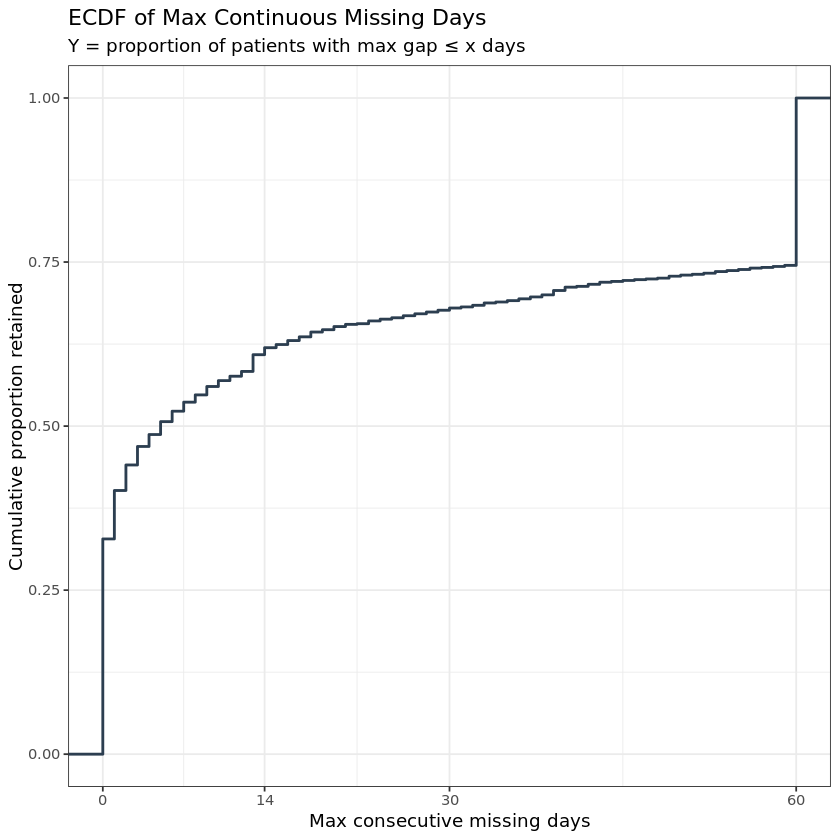

In [66]:
p_ecdf <- gap_summary |>
  mutate(max_gap = pmin(max_gap, 60)) |>
  ggplot(aes(x = max_gap)) +
  stat_ecdf(color = "#2C3E50", linewidth = 0.8) +
  scale_x_continuous(limits = c(0, 60),
                     breaks = c(0, 14, 30, 60)) +
  #scale_y_continuous(labels = scales::percent) +
  labs(title    = "ECDF of Max Continuous Missing Days",
       subtitle = "Y = proportion of patients with max gap ≤ x days",
       x = "Max consecutive missing days",
       y = "Cumulative proportion retained") +
  theme_bw(base_size = 11)
p_ecdf
#ggsave(p_ecdf, filename = paste0(path.out, 'activity_missing_gap.png'), width = 9, height = 5);


[1] "person_id"     "first_date"    "last_date"     "followup_days"
[5] "total_missing" "n_gaps"        "max_gap"       "mean_gap"     
[9] "gap_lengths"